# examine the predictions generated on MIMIC IV

# Note: Some suggestions from Gemini regarding architectural and training changes which could be implemented to improve the model's performance:

Architectural Refinements (Improving Risk Modeling): The goal here is to help the model better capture the long-term, subtle risk factors and to improve the output probability distribution.

    1. Augment the Input Window and Feature SetYou are using a 72-hour window. This is a solid standard, but late-stage prognosis often depends on the total accumulated history beyond the immediate 72 hours.
        Change: Instead of only feeding the last 72 hours, try to include a compressed representation of the entire prior history.
        Method:Add a Summary Vector (e.g., mean/std/min/max of key features over the entire stay up to time $L$).Concatenate this Summary Vector with the hidden state output from the RNN before the attention head.

    2. Refine the Temporal Attention MechanismSince the AUC drops late, the model might be focusing on less relevant short-term features when the patient is stable (i.e., when the relevant information is subtle or long-term).
        Change: Experiment with Self-Attention (like a Transformer block) instead of, or in addition to, the temporal attention mechanism.
        Benefit: Self-attention allows the model to globally weigh the importance of all time steps within the 72-hour window against each other, not just against the final context, potentially capturing more complex dependencies.

    3. Address the S-Curve with Output Refinement: The S-curve (under-predicting low risk, over-predicting mid-risk) suggests the final prediction heads might not be perfectly modeling the true probability distribution.
        Change: Increase the capacity of the prediction heads.
        Method: Add more layers or wider layers to the final Multi-Layer Perceptrons (MLPs) that form your prediction heads. This gives them more capacity to learn the non-linear mapping from the context vector to the time-to-event probability mass function (PMF), potentially smoothing the probability assignments at the extremes.

Training Regimen and Loss Function (Addressing Imbalance and Calibration): The high AUPRC suggests your model is good at the loss function optimization, but the $0.4 \to 0.6$ rise and the S-curve indicate the loss function could be refined to focus more aggressively on the minority event and calibration.
    
    1. Calibration-Aware Loss FunctionTo directly address the S-curve calibration issue, integrate a term that penalizes miscalibration.
        Change: Use the standard DeepHit loss (Likelihood + Ranking) but add a calibration loss term to the overall objective function ($\mathcal{L}$).
        Method: Implement the Expected Calibration Error (ECE) or a simpler mean-squared error (MSE) penalty between the predicted probability and the true outcome (observed incidence) on your minibatches.$$\mathcal{L}_{\text{Total}} = \mathcal{L}_{\text{DeepHit}} + \lambda \mathcal{L}_{\text{Calibration}}$$This forces the model not just to rank correctly, but to output well-calibrated probabilities during training.
    
    2. Address Imbalance in Loss WeightingGiven the $15\%$ death rate, you need to ensure the model doesn't ignore the rare event to satisfy the majority.
        Change: Weight the loss function for the Death event more heavily.
        Method: Increase the weight of the Cause-Specific Likelihood term ($\mathcal{L}_{C}$) for the Death event compared to the Discharge event within the DeepHit loss formulation. This makes mistakes on the Death event more costly to the model.
        
    3. Learning Rate SchedulingThe drop in AUC/AUPRC late in the stay could be due to the model getting stuck in local minima after many hours of highly variable data.
        Change: Employ a cyclic or cosine learning rate scheduler.
        Benefit: This helps the model jump out of shallow local minima, potentially finding a better optimum that performs more robustly across all Landmark Times $L$, especially for the complex, late-stage patients.

In [45]:
import os
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, average_precision_score


In [3]:
final_model_dir = "/home/jake/Documents/AI_Clinician/dynamic_deephit_results/mimic_iv/final_model"

# get the directory inside final_model_dir
inner_dir = os.listdir(final_model_dir)[0]
final_model_dir = os.path.join(final_model_dir, inner_dir)
final_model_dir


'/home/jake/Documents/AI_Clinician/dynamic_deephit_results/mimic_iv/final_model/mimic_iv_dynamic_deephit_discharge_mortality_tte_standard_20251201_180406_275977_job1208716.pbs-7'

In [4]:
# load test_set_predictions.parquet
test_set_predictions_path = Path(final_model_dir) / "test_set_predictions.parquet"
test_set_predictions = pd.read_parquet(test_set_predictions_path)
test_set_predictions.head(65)


,stay_id,event_label,time_to_event(hours),time_to_event,probs_discharge_bin0: 0h-6h,probs_discharge_bin1: 6h-12h,probs_discharge_bin2: 12h-24h,probs_discharge_bin3: 24h-48h,probs_discharge_bin4: 48h-168h,probs_discharge_bin5: 168h-336h,probs_discharge_bin6: 336h-1440h,probs_mortality_bin0: 0h-6h,probs_mortality_bin1: 6h-12h,probs_mortality_bin2: 12h-24h,probs_mortality_bin3: 24h-48h,probs_mortality_bin4: 48h-168h,probs_mortality_bin5: 168h-336h,probs_mortality_bin6: 336h-1440h
0,30000484,discharge,64,4,0.001481,0.004611,0.029901,0.224519,0.392618,0.115672,0.040234,0.002968,0.006584,0.015516,0.032635,0.066226,0.046270,0.020765
1,30000484,discharge,63,4,0.001483,0.004609,0.029843,0.224195,0.392550,0.115804,0.040283,0.002973,0.006598,0.015549,0.032693,0.066326,0.046314,0.020779
2,30000484,discharge,62,4,0.001486,0.004608,0.029784,0.223867,0.392481,0.115938,0.040332,0.002978,0.006613,0.015583,0.032752,0.066428,0.046359,0.020792
3,30000484,discharge,61,4,0.001488,0.004606,0.029724,0.223532,0.392411,0.116074,0.040383,0.002983,0.006627,0.015616,0.032811,0.066532,0.046405,0.020806
4,30000484,discharge,60,4,0.001491,0.004604,0.029662,0.223190,0.392341,0.116213,0.040436,0.002989,0.006641,0.015650,0.032871,0.066638,0.046452,0.020821
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,30000484,discharge,4,0,0.434655,0.056511,0.254690,0.086059,0.024215,0.003287,0.000589,0.032434,0.030185,0.032594,0.027757,0.013473,0.002916,0.000635
61,30000484,discharge,3,0,0.269987,0.075340,0.350460,0.107400,0.033210,0.004871,0.000865,0.030329,0.035121,0.039746,0.033035,0.015510,0.003405,0.000722
62,30000484,discharge,2,0,0.276542,0.094493,0.333948,0.095208,0.028386,0.004362,0.000831,0.032993,0.037986,0.042099,0.033841,0.015160,0.003412,0.000737
63,30000484,discharge,1,0,0.205888,0.137544,0.351721,0.095369,0.029802,0.004678,0.000915,0.032841,0.041773,0.045133,0.035157,0.015049,0.003399,0.000730


In [5]:
# make a list of the unique time_to_event values
unique_time_to_event = test_set_predictions['time_to_event'].unique()
unique_time_to_event.sort()
unique_time_to_event

array([0, 1, 2, 3, 4, 5, 6])

In [6]:
# make a list of the discharge columns
discharge_columns = [col for col in test_set_predictions.columns if 'discharge' in col]
discharge_columns

['probs_discharge_bin0: 0h-6h',
 'probs_discharge_bin1: 6h-12h',
 'probs_discharge_bin2: 12h-24h',
 'probs_discharge_bin3: 24h-48h',
 'probs_discharge_bin4: 48h-168h',
 'probs_discharge_bin5: 168h-336h',
 'probs_discharge_bin6: 336h-1440h']

In [7]:
# make a list of the mortality columns
mortality_columns = [col for col in test_set_predictions.columns if 'mortality' in col]
mortality_columns

['probs_mortality_bin0: 0h-6h',
 'probs_mortality_bin1: 6h-12h',
 'probs_mortality_bin2: 12h-24h',
 'probs_mortality_bin3: 24h-48h',
 'probs_mortality_bin4: 48h-168h',
 'probs_mortality_bin5: 168h-336h',
 'probs_mortality_bin6: 336h-1440h']

# build heatmap for discharge

In [8]:
discharge_df = test_set_predictions[test_set_predictions['event_label'] == 'discharge']
discharge_df

,stay_id,event_label,time_to_event(hours),time_to_event,probs_discharge_bin0: 0h-6h,probs_discharge_bin1: 6h-12h,probs_discharge_bin2: 12h-24h,probs_discharge_bin3: 24h-48h,probs_discharge_bin4: 48h-168h,probs_discharge_bin5: 168h-336h,probs_discharge_bin6: 336h-1440h,probs_mortality_bin0: 0h-6h,probs_mortality_bin1: 6h-12h,probs_mortality_bin2: 12h-24h,probs_mortality_bin3: 24h-48h,probs_mortality_bin4: 48h-168h,probs_mortality_bin5: 168h-336h,probs_mortality_bin6: 336h-1440h
0,30000484,discharge,64,4,0.001481,0.004611,0.029901,0.224519,0.392618,0.115672,0.040234,0.002968,0.006584,0.015516,0.032635,0.066226,0.046270,0.020765
1,30000484,discharge,63,4,0.001483,0.004609,0.029843,0.224195,0.392550,0.115804,0.040283,0.002973,0.006598,0.015549,0.032693,0.066326,0.046314,0.020779
2,30000484,discharge,62,4,0.001486,0.004608,0.029784,0.223867,0.392481,0.115938,0.040332,0.002978,0.006613,0.015583,0.032752,0.066428,0.046359,0.020792
3,30000484,discharge,61,4,0.001488,0.004606,0.029724,0.223532,0.392411,0.116074,0.040383,0.002983,0.006627,0.015616,0.032811,0.066532,0.046405,0.020806
4,30000484,discharge,60,4,0.001491,0.004604,0.029662,0.223190,0.392341,0.116213,0.040436,0.002989,0.006641,0.015650,0.032871,0.066638,0.046452,0.020821
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1224288,39997955,discharge,5,0,0.398465,0.243795,0.090653,0.161104,0.087959,0.014154,0.002220,0.000217,0.000206,0.000194,0.000230,0.000382,0.000239,0.000181
1224289,39997955,discharge,4,0,0.336952,0.217158,0.113811,0.197585,0.109866,0.019086,0.003078,0.000348,0.000325,0.000301,0.000347,0.000554,0.000338,0.000253
1224290,39997955,discharge,3,0,0.382249,0.177532,0.131068,0.187850,0.100453,0.016511,0.002463,0.000259,0.000234,0.000225,0.000264,0.000431,0.000262,0.000198
1224291,39997955,discharge,2,0,0.334781,0.139642,0.175764,0.209510,0.114745,0.019902,0.003022,0.000348,0.000310,0.000307,0.000369,0.000621,0.000388,0.000291


In [9]:
# build an array of discharge probabilities for each unique time_to_event
discharge_probabilities = []
for time in unique_time_to_event:
    df_temp = discharge_df[discharge_df['time_to_event'] == time]
    discharge_prob = df_temp[discharge_columns].mean().values
    discharge_probabilities.append(discharge_prob)

discharge_probabilities = np.array(discharge_probabilities)
discharge_probabilities

array([[0.51062053, 0.19573028, 0.11623935, 0.08286206, 0.04225131,
        0.0087633 , 0.00240724],
       [0.3149422 , 0.2928061 , 0.16304627, 0.11135139, 0.05862301,
        0.01144051, 0.00306338],
       [0.21425503, 0.19880708, 0.26405016, 0.15973091, 0.08783302,
        0.01700694, 0.00463715],
       [0.19584598, 0.1746234 , 0.20159695, 0.18687314, 0.12556009,
        0.02985968, 0.00905939],
       [0.14009401, 0.12417033, 0.15258883, 0.182704  , 0.17250285,
        0.06385221, 0.02327126],
       [0.0796169 , 0.07357964, 0.09684024, 0.1511053 , 0.20077278,
        0.10771774, 0.04581231],
       [0.05304218, 0.04851181, 0.0698232 , 0.12155367, 0.18920866,
        0.12190874, 0.05648015]], dtype=float32)

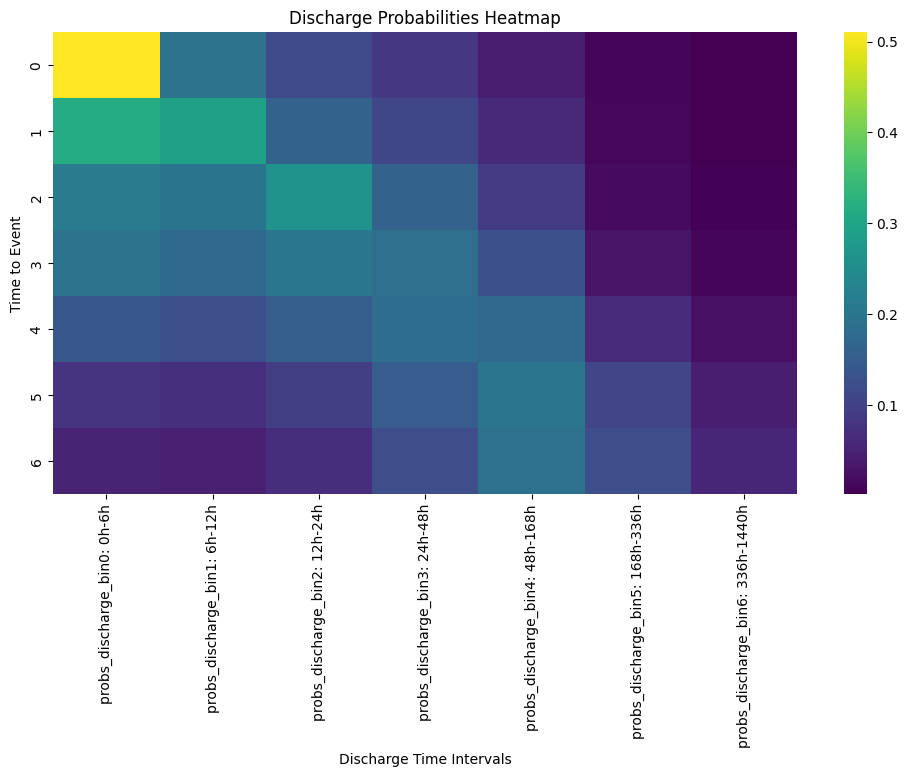

In [10]:
# plot the discharge probabilities as a heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(discharge_probabilities, xticklabels=discharge_columns, yticklabels=unique_time_to_event, cmap="viridis")
# make x labels 
plt.xlabel("Discharge Time Intervals")
plt.ylabel("Time to Event")
plt.title("Discharge Probabilities Heatmap")
plt.show()


In [11]:
mortality_df = test_set_predictions[test_set_predictions['event_label'] == 'mortality']
mortality_df

,stay_id,event_label,time_to_event(hours),time_to_event,probs_discharge_bin0: 0h-6h,probs_discharge_bin1: 6h-12h,probs_discharge_bin2: 12h-24h,probs_discharge_bin3: 24h-48h,probs_discharge_bin4: 48h-168h,probs_discharge_bin5: 168h-336h,probs_discharge_bin6: 336h-1440h,probs_mortality_bin0: 0h-6h,probs_mortality_bin1: 6h-12h,probs_mortality_bin2: 12h-24h,probs_mortality_bin3: 24h-48h,probs_mortality_bin4: 48h-168h,probs_mortality_bin5: 168h-336h,probs_mortality_bin6: 336h-1440h
683,30006983,mortality,990,6,0.017507,0.035194,0.107709,0.179002,0.115523,0.017783,0.003510,0.040254,0.092584,0.129699,0.140914,0.091913,0.022902,0.005505
684,30006983,mortality,989,6,0.018120,0.035038,0.109944,0.185595,0.114941,0.016465,0.002899,0.040157,0.089692,0.126119,0.140752,0.092177,0.022689,0.005414
685,30006983,mortality,988,6,0.010774,0.034377,0.132685,0.213481,0.139207,0.024468,0.006377,0.025327,0.072372,0.104934,0.116339,0.086117,0.026389,0.007152
686,30006983,mortality,987,6,0.014502,0.037586,0.171048,0.233636,0.120423,0.014442,0.002180,0.036202,0.070210,0.097103,0.108620,0.071794,0.017977,0.004276
687,30006983,mortality,986,6,0.008783,0.034154,0.207533,0.266448,0.131504,0.014358,0.002104,0.025301,0.054331,0.079328,0.092539,0.063438,0.016359,0.003822
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1222731,39979841,mortality,5,0,0.001320,0.002378,0.006487,0.027351,0.141639,0.118927,0.059784,0.053564,0.090092,0.121087,0.124412,0.114582,0.088673,0.049704
1222732,39979841,mortality,4,0,0.000992,0.001239,0.005367,0.025858,0.127473,0.109578,0.053519,0.033861,0.066286,0.126027,0.174995,0.146115,0.088446,0.040244
1222733,39979841,mortality,3,0,0.000576,0.000776,0.002624,0.010033,0.052423,0.050666,0.025571,0.199685,0.171410,0.186446,0.153178,0.076979,0.045348,0.024286
1222734,39979841,mortality,2,0,0.000737,0.000893,0.002885,0.011318,0.060861,0.060721,0.031098,0.133819,0.152399,0.193451,0.173636,0.094990,0.054543,0.028649


In [12]:
# build an array of mortality probabilities for each unique time_to_event
mortality_probabilities = []
for time in unique_time_to_event:
    df_temp = mortality_df[mortality_df['time_to_event'] == time]
    mortality_prob = df_temp[mortality_columns].mean().values
    mortality_probabilities.append(mortality_prob)

mortality_probabilities = np.array(mortality_probabilities)
mortality_probabilities

array([[0.29219782, 0.15851273, 0.09798972, 0.06343865, 0.03655651,
        0.0155084 , 0.00633225],
       [0.17014192, 0.16364294, 0.12171769, 0.08483215, 0.05101154,
        0.02186426, 0.00852047],
       [0.11710073, 0.13682504, 0.12207242, 0.09642546, 0.06250947,
        0.02718635, 0.01026441],
       [0.08758344, 0.11003865, 0.11047984, 0.1015035 , 0.07335822,
        0.03324356, 0.01227601],
       [0.06431285, 0.0887813 , 0.10034703, 0.1066541 , 0.08715851,
        0.04215245, 0.01548863],
       [0.0582388 , 0.0826271 , 0.09571464, 0.10648368, 0.0932477 ,
        0.04766219, 0.01834203],
       [0.05688192, 0.08532471, 0.10112703, 0.11461612, 0.10316472,
        0.05430118, 0.02173915]], dtype=float32)

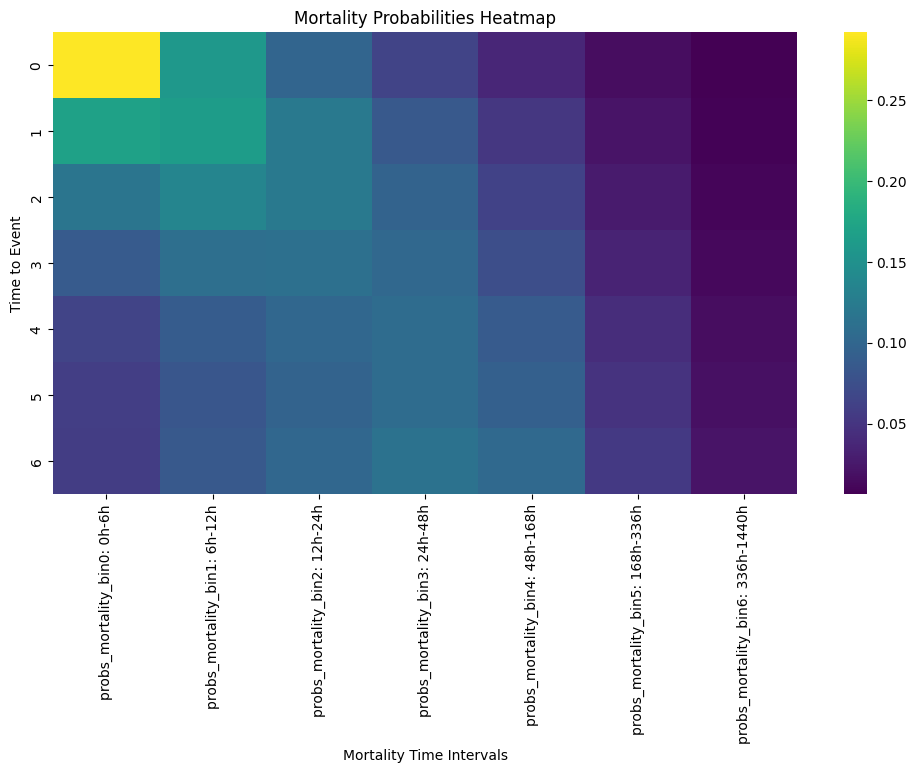

In [13]:
# plot the discharge probabilities as a heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(mortality_probabilities, xticklabels=mortality_columns, yticklabels=unique_time_to_event, cmap="viridis")
# make x labels 
plt.xlabel("Mortality Time Intervals")
plt.ylabel("Time to Event")
plt.title("Mortality Probabilities Heatmap")
plt.show()

# Landmark AUC and AUPRC
## fix the prediction horizon, and select a number of landmark times

In [21]:
# create a new column, time. For each stay_id, time starts at 0 and increments by 1 for each row
test_set_predictions['time'] = test_set_predictions.groupby('stay_id').cumcount()

# place the time column after event label
cols = test_set_predictions.columns.tolist()
cols.insert(cols.index('event_label') + 1, cols.pop(cols.index('time')))
test_set_predictions = test_set_predictions[cols]

test_set_predictions.tail(117)


,stay_id,event_label,time,time_to_event(hours),time_to_event,probs_discharge_bin0: 0h-6h,probs_discharge_bin1: 6h-12h,probs_discharge_bin2: 12h-24h,probs_discharge_bin3: 24h-48h,probs_discharge_bin4: 48h-168h,probs_discharge_bin5: 168h-336h,probs_discharge_bin6: 336h-1440h,probs_mortality_bin0: 0h-6h,probs_mortality_bin1: 6h-12h,probs_mortality_bin2: 12h-24h,probs_mortality_bin3: 24h-48h,probs_mortality_bin4: 48h-168h,probs_mortality_bin5: 168h-336h,probs_mortality_bin6: 336h-1440h
1224176,39997370,discharge,94,2,0,0.694716,0.107275,0.093033,0.052616,0.014712,0.001499,0.000210,0.010092,0.008577,0.006411,0.005845,0.003732,0.001017,0.000264
1224177,39997370,discharge,95,1,0,0.476168,0.151437,0.188282,0.099770,0.031032,0.002909,0.000372,0.010424,0.011784,0.010047,0.009319,0.006180,0.001807,0.000469
1224178,39997955,discharge,0,115,4,0.020309,0.056358,0.226896,0.340191,0.270062,0.059105,0.016316,0.000603,0.000826,0.001116,0.001578,0.003114,0.002162,0.001365
1224179,39997955,discharge,1,114,4,0.012567,0.046771,0.230955,0.353115,0.276462,0.055728,0.014582,0.000513,0.000758,0.001038,0.001452,0.002845,0.001979,0.001234
1224180,39997955,discharge,2,113,4,0.009495,0.040951,0.234242,0.364967,0.277731,0.050845,0.012607,0.000457,0.000711,0.000985,0.001362,0.002652,0.001849,0.001147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1224288,39997955,discharge,110,5,0,0.398465,0.243795,0.090653,0.161104,0.087959,0.014154,0.002220,0.000217,0.000206,0.000194,0.000230,0.000382,0.000239,0.000181
1224289,39997955,discharge,111,4,0,0.336952,0.217158,0.113811,0.197585,0.109866,0.019086,0.003078,0.000348,0.000325,0.000301,0.000347,0.000554,0.000338,0.000253
1224290,39997955,discharge,112,3,0,0.382249,0.177532,0.131068,0.187850,0.100453,0.016511,0.002463,0.000259,0.000234,0.000225,0.000264,0.000431,0.000262,0.000198
1224291,39997955,discharge,113,2,0,0.334781,0.139642,0.175764,0.209510,0.114745,0.019902,0.003022,0.000348,0.000310,0.000307,0.000369,0.000621,0.000388,0.000291


In [25]:
timebins = [0, 6, 12, 24, 48, 168, 336, 1440]
landmark_times = [0, 6, 12, 24, 48, 72]
target_time = 72

fractional_weights = []
for i in range(len(timebins) - 1):
    start = timebins[i]
    end = timebins[i + 1]
    if end <= target_time:
        fractional_weights.append(1.0)
    elif start >= target_time:
        fractional_weights.append(0.0)
    else:
        fractional_weight = (target_time - start) / (end - start)
        fractional_weights.append(fractional_weight)
fractional_weights


[1.0, 1.0, 1.0, 1.0, 0.2, 0.0, 0.0]

Landmark time: 0 hours
AUC: 0.7826, AUPRC: 0.9577
Landmark time: 6 hours
AUC: 0.8120, AUPRC: 0.9656
Landmark time: 12 hours
AUC: 0.8289, AUPRC: 0.9696
Landmark time: 24 hours
AUC: 0.8304, AUPRC: 0.9687
Landmark time: 48 hours
AUC: 0.8237, AUPRC: 0.9611
Landmark time: 72 hours
AUC: 0.8206, AUPRC: 0.9541


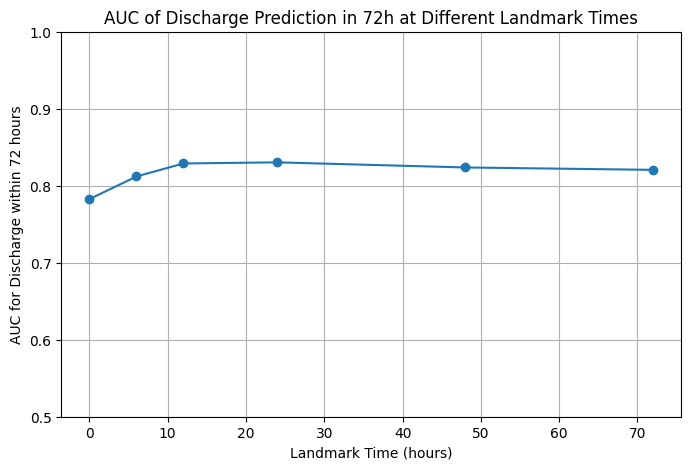

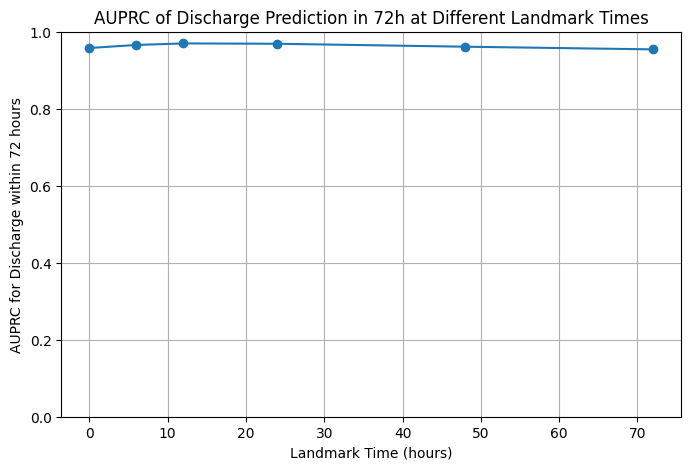

Landmark time: 0 hours
AUC: 0.8094, AUPRC: 0.3785
Landmark time: 6 hours
AUC: 0.8353, AUPRC: 0.4316
Landmark time: 12 hours
AUC: 0.8624, AUPRC: 0.4931
Landmark time: 24 hours
AUC: 0.8699, AUPRC: 0.5186
Landmark time: 48 hours
AUC: 0.8589, AUPRC: 0.5579
Landmark time: 72 hours
AUC: 0.8544, AUPRC: 0.5722


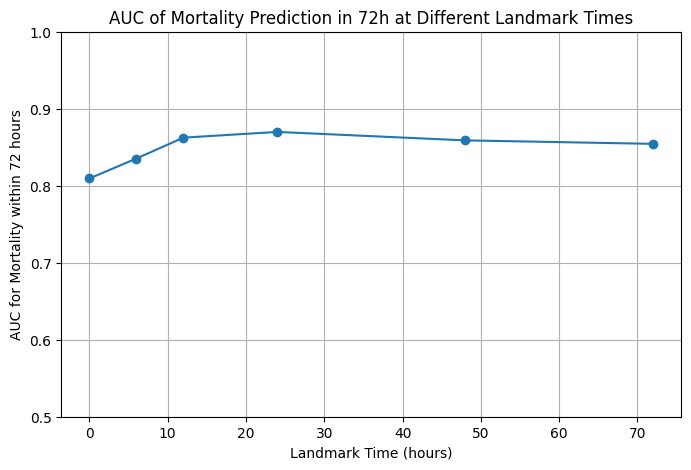

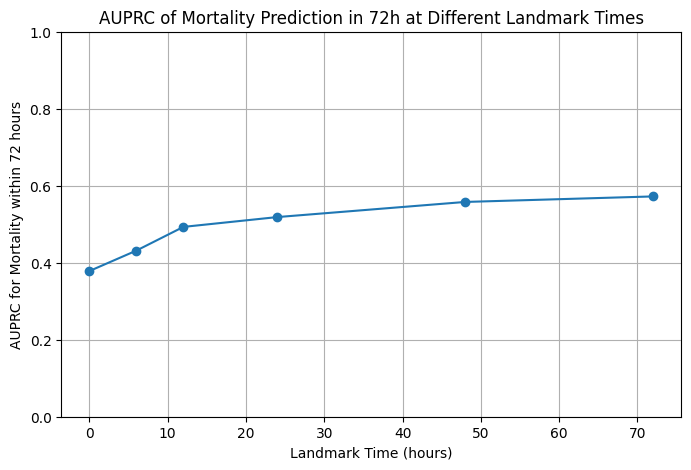

In [40]:
events = ['discharge', 'mortality']

for e in events:

    # for discharge
    auc_results = {}
    auprc_results = {}
    for t in landmark_times:
        print(f"Landmark time: {t} hours")
        df_temp = test_set_predictions[test_set_predictions['time'] == t]
        
        # outcome = 1 if event_label is discharge and time_to_event <= t + target_time
        outcome = []
        cumulative_prob = []
        for index, row in df_temp.iterrows():
            if row['event_label'] == e and row['time_to_event'] <= t + target_time:
                outcome.append(1)
            else:
                outcome.append(0)
            
            # calculate cumulative probability of discharge within target_time
            prob = 0.0
            if e == 'discharge':
                columns = discharge_columns
            else:
                columns = mortality_columns

            for i in range(len(columns)):            
                prob += row[columns[i]] * fractional_weights[i]
            cumulative_prob.append(prob)
        # calculate AUC
        auc = roc_auc_score(outcome, cumulative_prob)
        auprc = average_precision_score(outcome, cumulative_prob)
        auc_results[t] = auc
        auprc_results[t] = auprc
        print(f"AUC: {auc:.4f}, AUPRC: {auprc:.4f}")

    # plot the auc results
    plt.figure(figsize=(8, 5))
    plt.plot(list(auc_results.keys()), list(auc_results.values()), marker='o')
    plt.xlabel("Landmark Time (hours)")
    plt.ylabel(f"AUC for {e.capitalize()} within {target_time} hours")
    plt.title(f"AUC of {e.capitalize()} Prediction in {target_time}h at Different Landmark Times")
    plt.ylim(0.5, 1.0)
    plt.grid()
    plt.show()

    # plot the auprc results
    plt.figure(figsize=(8, 5))
    plt.plot(list(auprc_results.keys()), list(auprc_results.values()), marker='o')
    plt.xlabel("Landmark Time (hours)")
    plt.ylabel(f"AUPRC for {e.capitalize()} within {target_time} hours")
    plt.title(f"AUPRC of {e.capitalize()} Prediction in {target_time}h at Different Landmark Times")
    plt.ylim(0.0, 1.0)
    plt.grid()
    plt.show()  


# Dynamic calibration

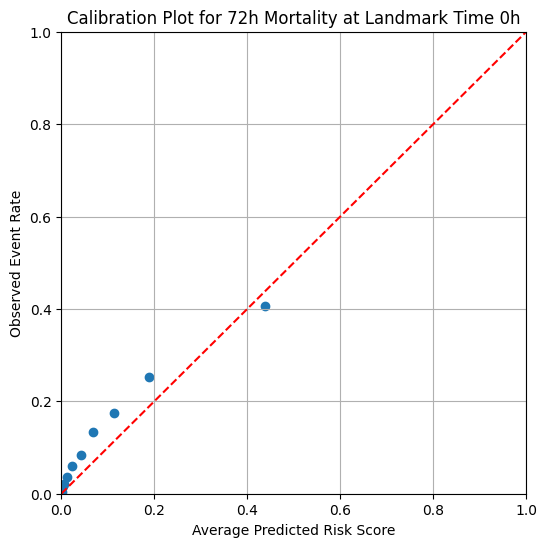

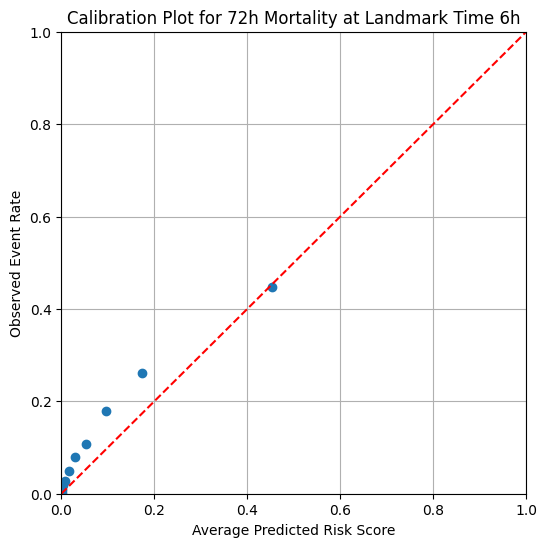

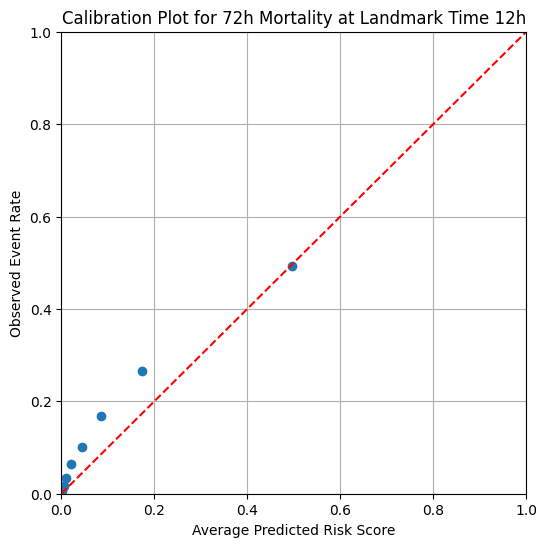

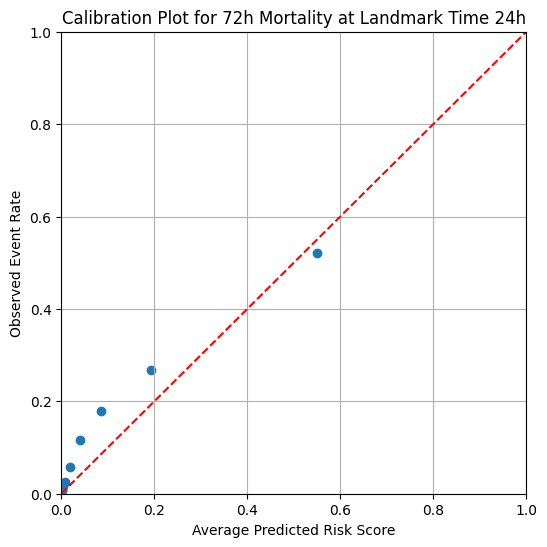

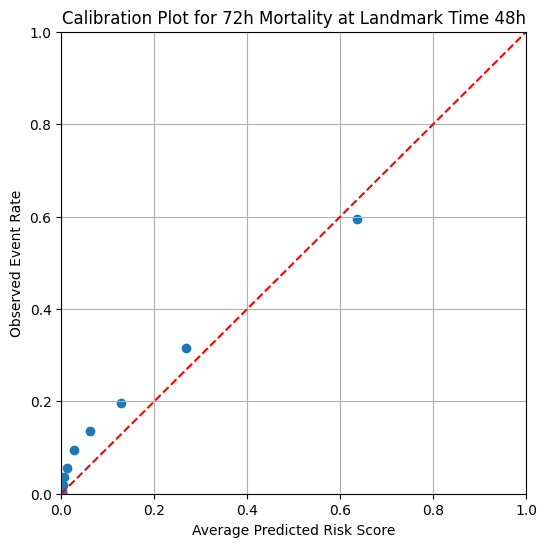

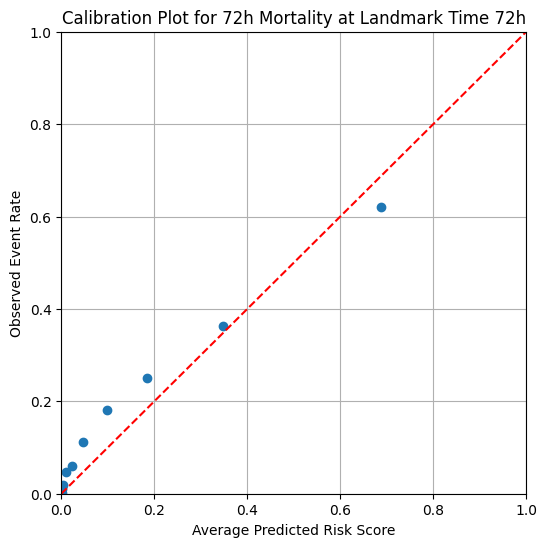

In [43]:
# timebins = [0, 6, 12, 24, 48, 168, 336, 1440]
landmark_times = [0, 6, 12, 24, 48, 72]
target_time = 72
e = 'mortality'

calibration_results = {}
for t in landmark_times:
    df_temp = test_set_predictions[test_set_predictions['time'] == t]

    cumulative_prob = []
    outcome = []
    for index, row in df_temp.iterrows():
        if row['event_label'] == e and row['time_to_event'] <= t + target_time:
            outcome.append(1)
        else:
            outcome.append(0)

        # calculate cumulative probability of discharge within target_time
        prob = 0.0
        if e == 'discharge':
            columns = discharge_columns
        else:
            columns = mortality_columns

        for i in range(len(columns)):            
            prob += row[columns[i]] * fractional_weights[i]
        cumulative_prob.append(prob)
    
    # group the results into deciles based on cumulative_prob
    df_results = pd.DataFrame({'outcome': outcome, 'cumulative_prob': cumulative_prob})
    df_results['decile'] = pd.qcut(df_results['cumulative_prob'], 10, labels=False)

    # calculate the average Risk score for each decile
    avg_risk_score = df_results.groupby('decile')['cumulative_prob'].mean()
    # calculate the Observed Conditional Cumulative Incidence for each decile
    observed_event_rate = df_results.groupby('decile')['outcome'].mean()

    calibration_results[t] = (avg_risk_score, observed_event_rate)

# plot calibration results as as scatter plot with a y=x line
for t in landmark_times:
    avg_risk_score, observed_event_rate = calibration_results[t]
    plt.figure(figsize=(6, 6))
    plt.scatter(avg_risk_score, observed_event_rate)
    plt.plot([0, 1], [0, 1], 'r--')
    plt.xlabel("Average Predicted Risk Score")
    plt.ylabel("Observed Event Rate")
    plt.title(f"Calibration Plot for {target_time}h {e.capitalize()} at Landmark Time {t}h")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid()
    plt.show()



# compute health score
$$
\text{H}_L = \sum_{j=1}^{N} \left[ (W_{\text{Discharge}} \cdot P_{j}^{\text{Discharge}} + W_{\text{Death}} \cdot P_{j}^{\text{Death}}) \cdot e^{-\lambda \cdot \text{Midpoint}_{j}} \right]
$$

### Will need to tune weights (positive for discharge, negative for death) during RL training, but let's compute some values now. Will probably need to tune $\lambda$ as well

In [54]:
midpoints = timebins[:-1] + np.diff(timebins) / 2
midpoints = midpoints.tolist()
midpoints

[3.0, 9.0, 18.0, 36.0, 108.0, 252.0, 888.0]

In [79]:
weight_discharge = 2
weight_mortality = -5
lambda_ = 0.1

In [80]:
# compute health score by looping through each probs_discharge and probs_mortality column
health_scores = np.zeros(len(test_set_predictions))

for i in range(len(discharge_columns)):
    health_scores += ((test_set_predictions[discharge_columns[i]] * weight_discharge) + \
                      (test_set_predictions[mortality_columns[i]] * weight_mortality)) * \
                        np.exp(-lambda_ * midpoints[i])

# add health_scores to test_set_predictions
test_set_predictions['health_score'] = health_scores 


In [81]:
# calculate average health scores for each type of event_label
avg_health_scores = test_set_predictions.groupby('event_label')['health_score'].mean()
avg_health_scores

event_label
discharge    0.300112
mortality   -0.459767
Name: health_score, dtype: float64

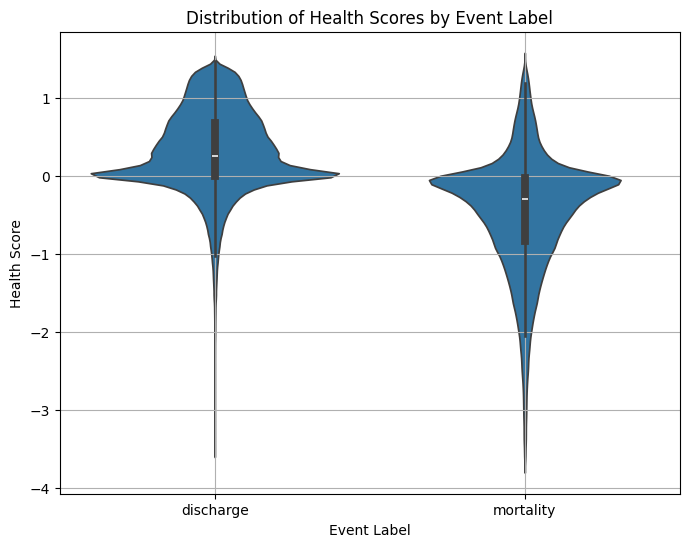

In [82]:
# create a violin plot of health scores by event_label
plt.figure(figsize=(8, 6))
sns.violinplot(x='event_label', y='health_score', data=test_set_predictions)
plt.xlabel("Event Label")
plt.ylabel("Health Score")
plt.title("Distribution of Health Scores by Event Label")
plt.grid()
plt.show()

In [83]:
# calculate statistical significance between health scores of discharge and mortality using t-test
from scipy.stats import ttest_ind
discharge_scores = test_set_predictions[test_set_predictions['event_label'] == 'discharge']['health_score']
mortality_scores = test_set_predictions[test_set_predictions['event_label'] == 'mortality']['health_score']
t_stat, p_value = ttest_ind(discharge_scores, mortality_scores)
print(f"T-statistic: {t_stat:.4f}, P-value: {p_value:.4f}")

T-statistic: 553.7712, P-value: 0.0000


In [85]:
time_bins

NameError: name 'time_bins' is not defined

In [ ]:
# calculate and plot health score for each event type by time_to_event (these are the binned tte values)
for e in events:
    for t in 

In [84]:
test_set_predictions

,stay_id,event_label,time,time_to_event(hours),time_to_event,probs_discharge_bin0: 0h-6h,probs_discharge_bin1: 6h-12h,probs_discharge_bin2: 12h-24h,probs_discharge_bin3: 24h-48h,probs_discharge_bin4: 48h-168h,probs_discharge_bin5: 168h-336h,probs_discharge_bin6: 336h-1440h,probs_mortality_bin0: 0h-6h,probs_mortality_bin1: 6h-12h,probs_mortality_bin2: 12h-24h,probs_mortality_bin3: 24h-48h,probs_mortality_bin4: 48h-168h,probs_mortality_bin5: 168h-336h,probs_mortality_bin6: 336h-1440h,health_score
0,30000484,discharge,0,64,4,0.001481,0.004611,0.029901,0.224519,0.392618,0.115672,0.040234,0.002968,0.006584,0.015516,0.032635,0.066226,0.046270,0.020765,-0.013553
1,30000484,discharge,1,63,4,0.001483,0.004609,0.029843,0.224195,0.392550,0.115804,0.040283,0.002973,0.006598,0.015549,0.032693,0.066326,0.046314,0.020779,-0.013670
2,30000484,discharge,2,62,4,0.001486,0.004608,0.029784,0.223867,0.392481,0.115938,0.040332,0.002978,0.006613,0.015583,0.032752,0.066428,0.046359,0.020792,-0.013789
3,30000484,discharge,3,61,4,0.001488,0.004606,0.029724,0.223532,0.392411,0.116074,0.040383,0.002983,0.006627,0.015616,0.032811,0.066532,0.046405,0.020806,-0.013909
4,30000484,discharge,4,60,4,0.001491,0.004604,0.029662,0.223190,0.392341,0.116213,0.040436,0.002989,0.006641,0.015650,0.032871,0.066638,0.046452,0.020821,-0.014031
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1224288,39997955,discharge,110,5,0,0.398465,0.243795,0.090653,0.161104,0.087959,0.014154,0.002220,0.000217,0.000206,0.000194,0.000230,0.000382,0.000239,0.000181,0.825982
1224289,39997955,discharge,111,4,0,0.336952,0.217158,0.113811,0.197585,0.109866,0.019086,0.003078,0.000348,0.000325,0.000301,0.000347,0.000554,0.000338,0.000253,0.722004
1224290,39997955,discharge,112,3,0,0.382249,0.177532,0.131068,0.187850,0.100453,0.016511,0.002463,0.000259,0.000234,0.000225,0.000264,0.000431,0.000262,0.000198,0.762655
1224291,39997955,discharge,113,2,0,0.334781,0.139642,0.175764,0.209510,0.114745,0.019902,0.003022,0.000348,0.000310,0.000307,0.000369,0.000621,0.000388,0.000291,0.676910
